In [1]:

import random
import time

import pandas as pd
import matplotlib.pyplot as plt

from structures.avl import AVLTree
from structures.RB import RedBlackTree


In [2]:

def generate_sequences(n, seed=42):

    values = list(range(1, n + 1))

    increasing = values.copy()
    decreasing = values[::-1]

    random_values = values.copy()

    rng = random.Random(seed)
    rng.shuffle(random_values)

    return {
        "Increasing": increasing,
        "Decreasing": decreasing,
        "Random": random_values
    }


In [3]:

sequences = generate_sequences(10)

for name, values in sequences.items():
    print(f"{name}: {values}")


Increasing: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Decreasing: [10, 9, 8, 7, 6, 5, 4, 3, 2, 1]
Random: [8, 4, 3, 9, 6, 7, 10, 5, 1, 2]


In [4]:

def benchmark_insert(tree_class, values):

    tree = tree_class()

    start = time.perf_counter()

    for value in values:
        tree.insert(value)

    elapsed = time.perf_counter() - start

    return {
        "Tree": tree_class.__name__,
        "Nodes": tree.count_nodes(),
        "Height": tree.height(),
        "Rotations": tree.rotations,
        "Color flips": getattr(tree, "color_flips", 0),
        "Insertion time (ms)": elapsed * 1000
    }


In [7]:

def benchmark_search(tree_class, values, repetitions=30):

    tree = tree_class()

    for value in values:
        tree.insert(value)

    assert tree.in_order() == sorted(values)

    if isinstance(tree, AVLTree):
        assert tree.is_valid_avl()
    else:
        assert tree.is_valid_rb()

    search_values = values.copy()

    times = []

    for _ in range(repetitions):

        start = time.perf_counter()

        for value in search_values:
            assert tree.search(value)

        elapsed = time.perf_counter() - start

        times.append(elapsed * 1000)

    return {
        "Tree": tree_class.__name__,
        "Nodes": tree.count_nodes(),
        "Height": tree.height(),
        "Mean search time (ms)": sum(times) / len(times),
        "Min search time (ms)": min(times),
        "Max search time (ms)": max(times)
    }


In [5]:

results = []

sequences = generate_sequences(100)

for sequence_name, values in sequences.items():

    for tree_class in [AVLTree, RedBlackTree]:

        result = benchmark_insert(tree_class, values)

        result["Sequence"] = sequence_name

        results.append(result)

df = pd.DataFrame(results)

df


,Tree,Nodes,Height,Rotations,Color flips,Insertion time (ms),Sequence
0,AVLTree,100,7,93,0,1.4989,Increasing
1,RedBlackTree,100,7,94,91,0.8535,Increasing
2,AVLTree,100,7,93,0,1.1236,Decreasing
3,RedBlackTree,100,9,91,91,1.0621,Decreasing
4,AVLTree,100,8,65,0,1.0795,Random
5,RedBlackTree,100,9,120,71,0.8667,Random


In [8]:

search_results = []

sequences = generate_sequences(100)

for sequence_name, values in sequences.items():

    for tree_class in [AVLTree, RedBlackTree]:

        result = benchmark_search(tree_class, values)

        result["Sequence"] = sequence_name

        search_results.append(result)

df_search = pd.DataFrame(search_results)

df_search.round(4)


,Tree,Nodes,Height,Mean search time (ms),Min search time (ms),Max search time (ms),Sequence
0,AVLTree,100,7,0.0528,0.0399,0.0761,Increasing
1,RedBlackTree,100,7,0.0772,0.0753,0.0942,Increasing
2,AVLTree,100,7,0.0764,0.0749,0.0963,Decreasing
3,RedBlackTree,100,9,0.0773,0.0756,0.0962,Decreasing
4,AVLTree,100,8,0.0804,0.0767,0.1451,Random
5,RedBlackTree,100,9,0.0791,0.0775,0.0971,Random


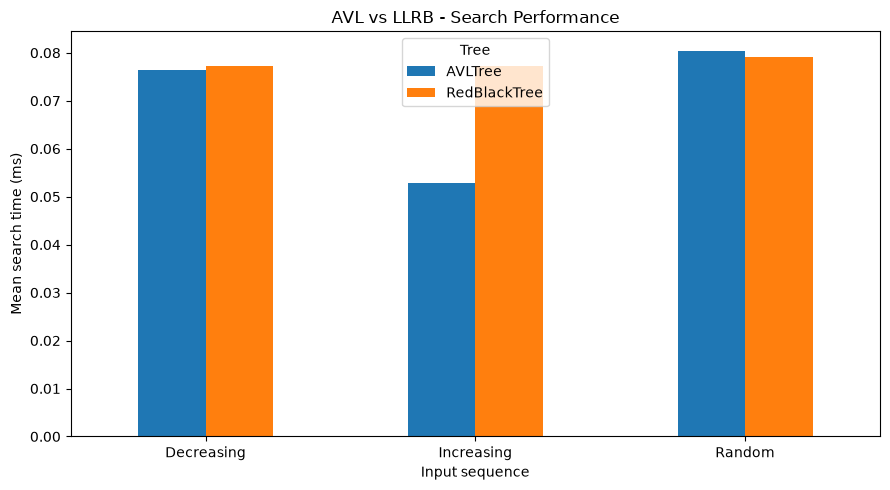

In [9]:

search_pivot = df_search.pivot(
    index="Sequence",
    columns="Tree",
    values="Mean search time (ms)"
)

search_pivot.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("AVL vs LLRB - Search Performance")
plt.ylabel("Mean search time (ms)")
plt.xlabel("Input sequence")
plt.xticks(rotation=0)
plt.legend(title="Tree")
plt.tight_layout()
plt.show()


In [10]:

def benchmark_unsuccessful_search(tree_class, values, repetitions=30):

    tree = tree_class()

    for value in values:
        tree.insert(value)

    missing_values = list(
        range(max(values) + 1, max(values) + len(values) + 1)
    )

    times = []

    for _ in range(repetitions):

        start = time.perf_counter()

        for value in missing_values:
            assert not tree.search(value)

        elapsed = time.perf_counter() - start

        times.append(elapsed * 1000)

    return {
        "Tree": tree_class.__name__,
        "Nodes": tree.count_nodes(),
        "Height": tree.height(),
        "Mean unsuccessful search time (ms)": (
            sum(times) / len(times)
        )
    }


In [11]:

unsuccessful_results = []

for sequence_name, values in generate_sequences(100).items():

    for tree_class in [AVLTree, RedBlackTree]:

        result = benchmark_unsuccessful_search(
            tree_class, values
        )

        result["Sequence"] = sequence_name

        unsuccessful_results.append(result)

df_unsuccessful = pd.DataFrame(unsuccessful_results)

df_unsuccessful.round(4)


,Tree,Nodes,Height,Mean unsuccessful search time (ms),Sequence
0,AVLTree,100,7,0.0942,Increasing
1,RedBlackTree,100,7,0.0922,Increasing
2,AVLTree,100,7,0.0958,Decreasing
3,RedBlackTree,100,9,0.0866,Decreasing
4,AVLTree,100,8,0.0956,Random
5,RedBlackTree,100,9,0.0903,Random
